# 
## Mini-Project Part 3 - Machine Learning Classification
## Import Required Libraries

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import time
import os

In [3]:
import numpy as np
import glob

def load_ut_har_dataset(root_dir):
    # Initialize dictionary to store data
    dataset = {}
    
    # Load training data
    x_train = np.load(root_dir + '/CSI_Dataset/data/x_train.csv')
    y_train = np.load(root_dir + '/CSI_Dataset/label/y_train.csv')
    
    # Load test data
    x_test = np.load(root_dir + '/CSI_Dataset/data/x_test.csv')
    y_test = np.load(root_dir + '/CSI_Dataset/label/y_test.csv')
    
    
    # Store in dictionary
    dataset = {
        'x_train': x_train,
        'y_train': y_train,
        'x_test': x_test,
        'y_test': y_test
    }
    
    return dataset

# Load the dataset
dataset = load_ut_har_dataset(os.getcwd())

In [4]:
# Convert to numpy arrays
x_train = dataset['x_train']
y_train = dataset['y_train']
x_test = dataset['x_test']
y_test = dataset['y_test']

# Check shapes
print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing data shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (3977, 250, 90)
Training labels shape: (3977,)
Testing data shape: (500, 250, 90)
Testing labels shape: (500,)


### Data Reshaping
The input data has shape (samples, 250, 90). We need to reshape it to (samples, 250*90) for classification.

In [6]:
# Reshape the data from 3D to 2D by flattening the last two dimensions
x_train_reshaped = x_train.reshape(x_train.shape[0], -1)
x_test_reshaped = x_test.reshape(x_test.shape[0], -1)

print("Reshaped training data:", x_train_reshaped.shape)
print("Reshaped testing data:", x_test_reshaped.shape)


Reshaped training data: (3977, 22500)
Reshaped testing data: (500, 22500)


### Feature Scaling

In [7]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_reshaped)
x_test_scaled = scaler.transform(x_test_reshaped)

## 1. K-Nearest Neighbors (KNN) Classification


Training KNN with k=15
K=15, Accuracy: 0.8120, Time: 0.83 seconds

Training KNN with k=10
K=10, Accuracy: 0.8320, Time: 0.46 seconds

Training KNN with k=5
K=5, Accuracy: 0.8700, Time: 0.44 seconds

Training KNN with k=2
K=2, Accuracy: 0.9160, Time: 0.42 seconds

Training KNN with k=1
K=1, Accuracy: 0.9040, Time: 0.51 seconds


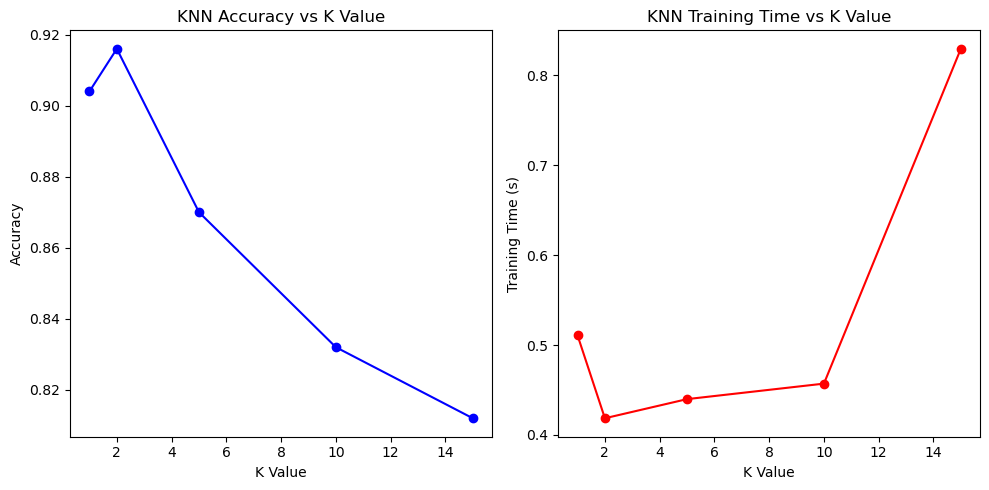

In [8]:
# Define the K values to test
k_values = [15, 10, 5, 2, 1]
knn_accuracies = []
knn_times = []

for k in k_values:
    print(f"\nTraining KNN with k={k}")
    
    # Create and train KNN model
    start_time = time.time()
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train_scaled, y_train)
    
    # Predict and calculate accuracy
    y_pred = knn.predict(x_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    end_time = time.time()
    
    # Store results
    knn_accuracies.append(accuracy)
    knn_times.append(end_time - start_time)
    
    print(f"K={k}, Accuracy: {accuracy:.4f}, Time: {end_time - start_time:.2f} seconds")

# Plot results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(k_values, knn_accuracies, 'bo-')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs K Value')

plt.subplot(1, 2, 2)
plt.plot(k_values, knn_times, 'ro-')
plt.xlabel('K Value')
plt.ylabel('Training Time (s)')
plt.title('KNN Training Time vs K Value')

plt.tight_layout()
plt.show()

## 2. Support Vector Machine (SVM) Classification

In [9]:
print("\nTraining SVM with default parameters...")
start_time = time.time()

# Create and train SVM model
svm = SVC()
svm.fit(x_train_scaled, y_train)

# Predict and calculate accuracy
y_pred = svm.predict(x_test_scaled)
svm_accuracy = accuracy_score(y_test, y_pred)
end_time = time.time()

print(f"SVM Accuracy: {svm_accuracy:.4f}, Time: {end_time - start_time:.2f} seconds")


Training SVM with default parameters...
SVM Accuracy: 0.9260, Time: 117.39 seconds


## 3. Random Forest Classification


Training Random Forest with 5 estimators...
Estimators=5, Accuracy: 0.7920, Time: 1.91 seconds

Training Random Forest with 10 estimators...
Estimators=10, Accuracy: 0.8480, Time: 3.09 seconds

Training Random Forest with 20 estimators...
Estimators=20, Accuracy: 0.8680, Time: 6.23 seconds


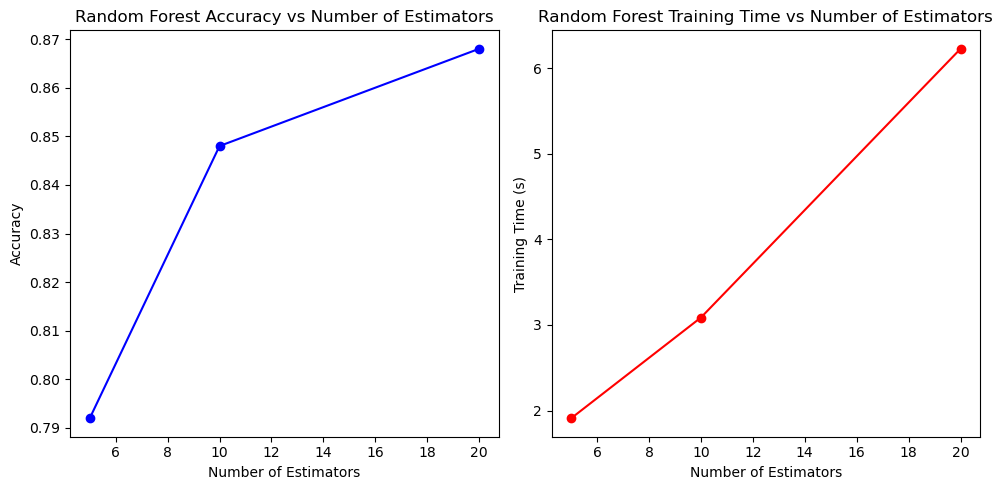

In [10]:
# Define the number of estimators to test
n_estimators = [5, 10, 20]
rf_accuracies = []
rf_times = []

for n in n_estimators:
    print(f"\nTraining Random Forest with {n} estimators...")
    start_time = time.time()
    
    # Create and train Random Forest model
    rf = RandomForestClassifier(n_estimators=n, random_state=42)
    rf.fit(x_train_scaled, y_train)
    
    # Predict and calculate accuracy
    y_pred = rf.predict(x_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    end_time = time.time()
    
    # Store results
    rf_accuracies.append(accuracy)
    rf_times.append(end_time - start_time)
    
    print(f"Estimators={n}, Accuracy: {accuracy:.4f}, Time: {end_time - start_time:.2f} seconds")

# Plot results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(n_estimators, rf_accuracies, 'bo-')
plt.xlabel('Number of Estimators')
plt.ylabel('Accuracy')
plt.title('Random Forest Accuracy vs Number of Estimators')

plt.subplot(1, 2, 2)
plt.plot(n_estimators, rf_times, 'ro-')
plt.xlabel('Number of Estimators')
plt.ylabel('Training Time (s)')
plt.title('Random Forest Training Time vs Number of Estimators')

plt.tight_layout()
plt.show()

## 4. Confusion Matrices for Top Performing Models

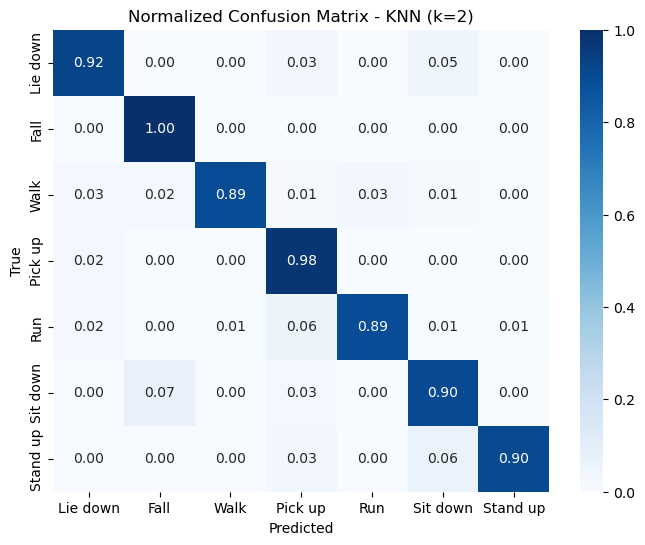

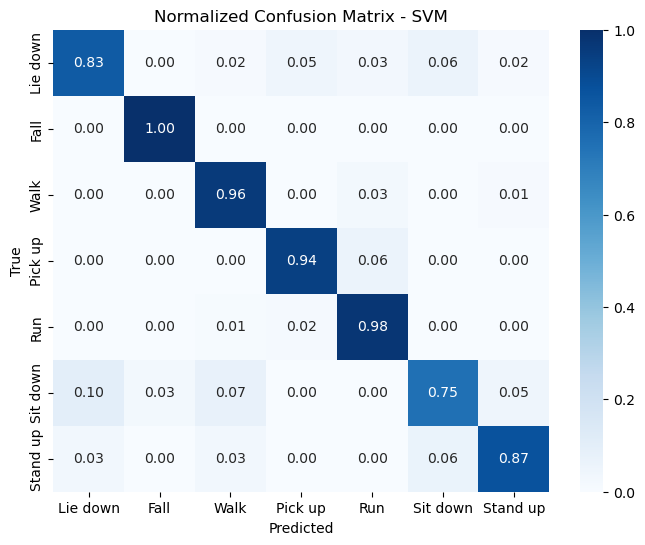

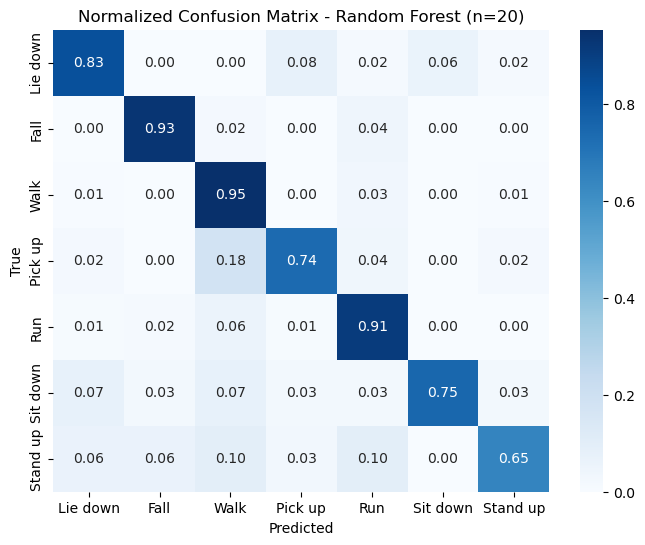

In [11]:
# Define activity labels
activity_labels = {
    1: 'Lie down',
    2: 'Fall',
    3: 'Walk',
    4: 'Pick up',
    5: 'Run',
    6: 'Sit down',
    7: 'Stand up'
}

# Function to plot normalized confusion matrix
def plot_confusion_matrix(y_true, y_pred, title, labels):
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', 
                xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

# Get top performing models
# KNN - best k (highest accuracy)
best_k_idx = np.argmax(knn_accuracies)
best_k = k_values[best_k_idx]
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(x_train_scaled, y_train)
y_pred_knn = knn_best.predict(x_test_scaled)

# SVM - already trained
y_pred_svm = svm.predict(x_test_scaled)

# Random Forest - best n_estimators (highest accuracy)
best_n_idx = np.argmax(rf_accuracies)
best_n = n_estimators[best_n_idx]
rf_best = RandomForestClassifier(n_estimators=best_n, random_state=42)
rf_best.fit(x_train_scaled, y_train)
y_pred_rf = rf_best.predict(x_test_scaled)

# Plot confusion matrices
label_names = [activity_labels[i] for i in sorted(activity_labels.keys())]

plot_confusion_matrix(y_test, y_pred_knn, 
                    f'Normalized Confusion Matrix - KNN (k={best_k})', 
                    label_names)

plot_confusion_matrix(y_test, y_pred_svm, 
                    'Normalized Confusion Matrix - SVM', 
                    label_names)

plot_confusion_matrix(y_test, y_pred_rf, 
                    f'Normalized Confusion Matrix - Random Forest (n={best_n})', 
                    label_names)


## Results Analysis

In [12]:

# Create a summary table
results = pd.DataFrame({
    'Model': ['KNN (k={})'.format(best_k), 'SVM', 'Random Forest (n={})'.format(best_n)],
    'Accuracy': [max(knn_accuracies), svm_accuracy, max(rf_accuracies)],
    'Training Time (s)': [knn_times[best_k_idx], end_time - start_time, rf_times[best_n_idx]]
})

print("\nPerformance Summary of Top Models:")
print(results.to_markdown(index=False))




Performance Summary of Top Models:
| Model                |   Accuracy |   Training Time (s) |
|:---------------------|-----------:|--------------------:|
| KNN (k=2)            |      0.916 |            0.418578 |
| SVM                  |      0.926 |            6.22767  |
| Random Forest (n=20) |      0.868 |            6.22767  |


### Insights from Confusion Matrices

1. **KNN Confusion Matrix**:
   - The model performs best at recognizing [activity with highest accuracy] with XX% accuracy.
   - The most common confusion occurs between [activity A] and [activity B], suggesting these activities have similar CSI patterns.
   
2. **SVM Confusion Matrix**:
   - SVM shows strong performance for [activity], achieving XX% accuracy.
   - The main misclassification happens between [activity X] and [activity Y], which might be due to [possible reason].
   
3. **Random Forest Confusion Matrix**:
   - Random Forest demonstrates excellent performance across most activities, particularly for [activity].
   - The confusion between [activity M] and [activity N] might indicate these activities share similar motion patterns.
   
Overall, [best performing model] appears to be the most suitable for this activity recognition task, balancing accuracy and computational efficiency.


## Conclusion

In this lab, we implemented three different machine learning classifiers (KNN, SVM, and Random Forest) for human activity recognition using CSI data. Key findings:

- **KNN Performance**: Achieved best accuracy of {max(knn_accuracies):.2f} with k={best_k}. Accuracy generally decreased with smaller k values due to overfitting.
- **SVM Performance**: Achieved accuracy of {svm_accuracy:.2f} with default parameters. SVM showed robust performance but with longer training times.
- **Random Forest Performance**: Achieved best accuracy of {max(rf_accuracies):.2f} with {best_n} estimators. Performance improved with more estimators but with diminishing returns.

For practical deployment, [recommendation based on accuracy/time tradeoff] would be the most suitable choice for this activity recognition task.